# PBMC Single-Cell RNA-seq Analysis

**Project:** Exploratory analysis of the 10x Genomics PBMC 3k dataset  
**Tools:** Python, Scanpy, AnnData, pandas, NumPy, Matplotlib  
**Environment:** Google Colab

## Project overview

This notebook follows a reproducible single-cell RNA-seq workflow:

1. Set up the Python environment and load the dataset.
2. Inspect the cell-by-gene expression matrix.
3. Calculate quality-control (QC) metrics and filter low-quality cells.
4. Normalize expression and identify highly variable genes.
5. Run PCA, construct a neighbour graph, calculate UMAP, and cluster cells.
6. Identify marker genes and assign broad cell-type labels.
7. Explore the cytotoxic lymphocyte cluster and create provisional NK/T-cell candidate labels.
8. Perform exploratory differential-expression comparisons and export results.

**Important:** Cell labels are provisional, marker-based annotations. In particular, splitting the cytotoxic lymphocyte cluster using CD3D positivity alone is an exploratory simplification, not definitive cell identification.

## 1. Environment setup

Run this cell in a fresh Google Colab runtime. Package installation may take a few minutes. If Colab asks for a runtime restart after installation, restart it and then continue from the imports cell.

In [1]:
%pip install -q "scanpy==1.11.4" "anndata==0.11.4" "pandas==2.2.3" "numpy==2.2.6" "bottleneck>=1.5" "zarr==2.18.7" igraph leidenalg

In [2]:
import os
import sys
import zarr
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Scanpy:", sc.__version__)
print("AnnData:", ad.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Zarr:", zarr.__version__)

sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=100, facecolor="white")

Python: 3.13.18
Scanpy: 1.11.4
AnnData: 0.11.4
pandas: 2.2.3
NumPy: 2.4.6
Zarr: 2.18.7


## 2. Download and load the PBMC 3k dataset

The dataset is a filtered 10x Genomics gene-expression matrix. The matrix is loaded into an `AnnData` object. In Scanpy, cells are rows and genes are columns.

In [3]:
# Download the dataset archive from 10x Genomics
!wget -O pbmc3k.tar.gz https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz

# Extract the archive
!tar -xzf pbmc3k.tar.gz

--2026-11-23 22:09:01--  https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz
Resolving cf.10xgenomics.com (cf.10xgenomics.com)... 104.18.0.173, 104.18.1.173, 2606:4700::6812:ad, ...
Connecting to cf.10xgenomics.com (cf.10xgenomics.com)|104.18.0.173|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7621991 (7.3M) [application/x-tar]
Saving to: ‘pbmc3k.tar.gz’

pbmc3k.tar.gz       100%[===================>]   7.27M  --.-KB/s    in 0.09s   

2026-11-23 22:09:01 (84.4 MB/s) - ‘pbmc3k.tar.gz’ saved [7621991/7621991]



In [4]:
adata = sc.read_10x_mtx(
    "filtered_gene_bc_matrices/hg19/",
    var_names="gene_symbols",
    cache=False
)
adata.var_names_make_unique()

print(adata)
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)
print("First five cell IDs:", adata.obs_names[:5].tolist())
print("First ten gene names:", adata.var_names[:10].tolist())

--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
Number of cells: 2700
Number of genes: 32738
First five cell IDs: ['AAACATACAACCAC-1', 'AAACATTGAGCTAC-1', 'AAACATTGATCAGC-1', 'AAACCGTGCTTCCG-1', 'AAACCGTGTATGCG-1']
First ten gene names: ['MIR1302-10', 'FAM138A', 'OR4F5', 'RP11-34P13.7', 'RP11-34P13.8', 'AL627309.1', 'RP11-34P13.14', 'RP11-34P13.9', 'AP006222.2', 'RP4-669L17.10']


## 3. Quality control (QC)

QC metrics help identify cells that may be low quality. Here we calculate:

- `n_genes_by_counts`: number of genes detected in each cell.
- `total_counts`: total number of recorded counts in each cell.
- `pct_counts_mt`: percentage of counts assigned to mitochondrial genes.

The thresholds below reproduce the filtering used in the original analysis. Thresholds should be evaluated using the QC distributions and biological context rather than treated as universal rules.

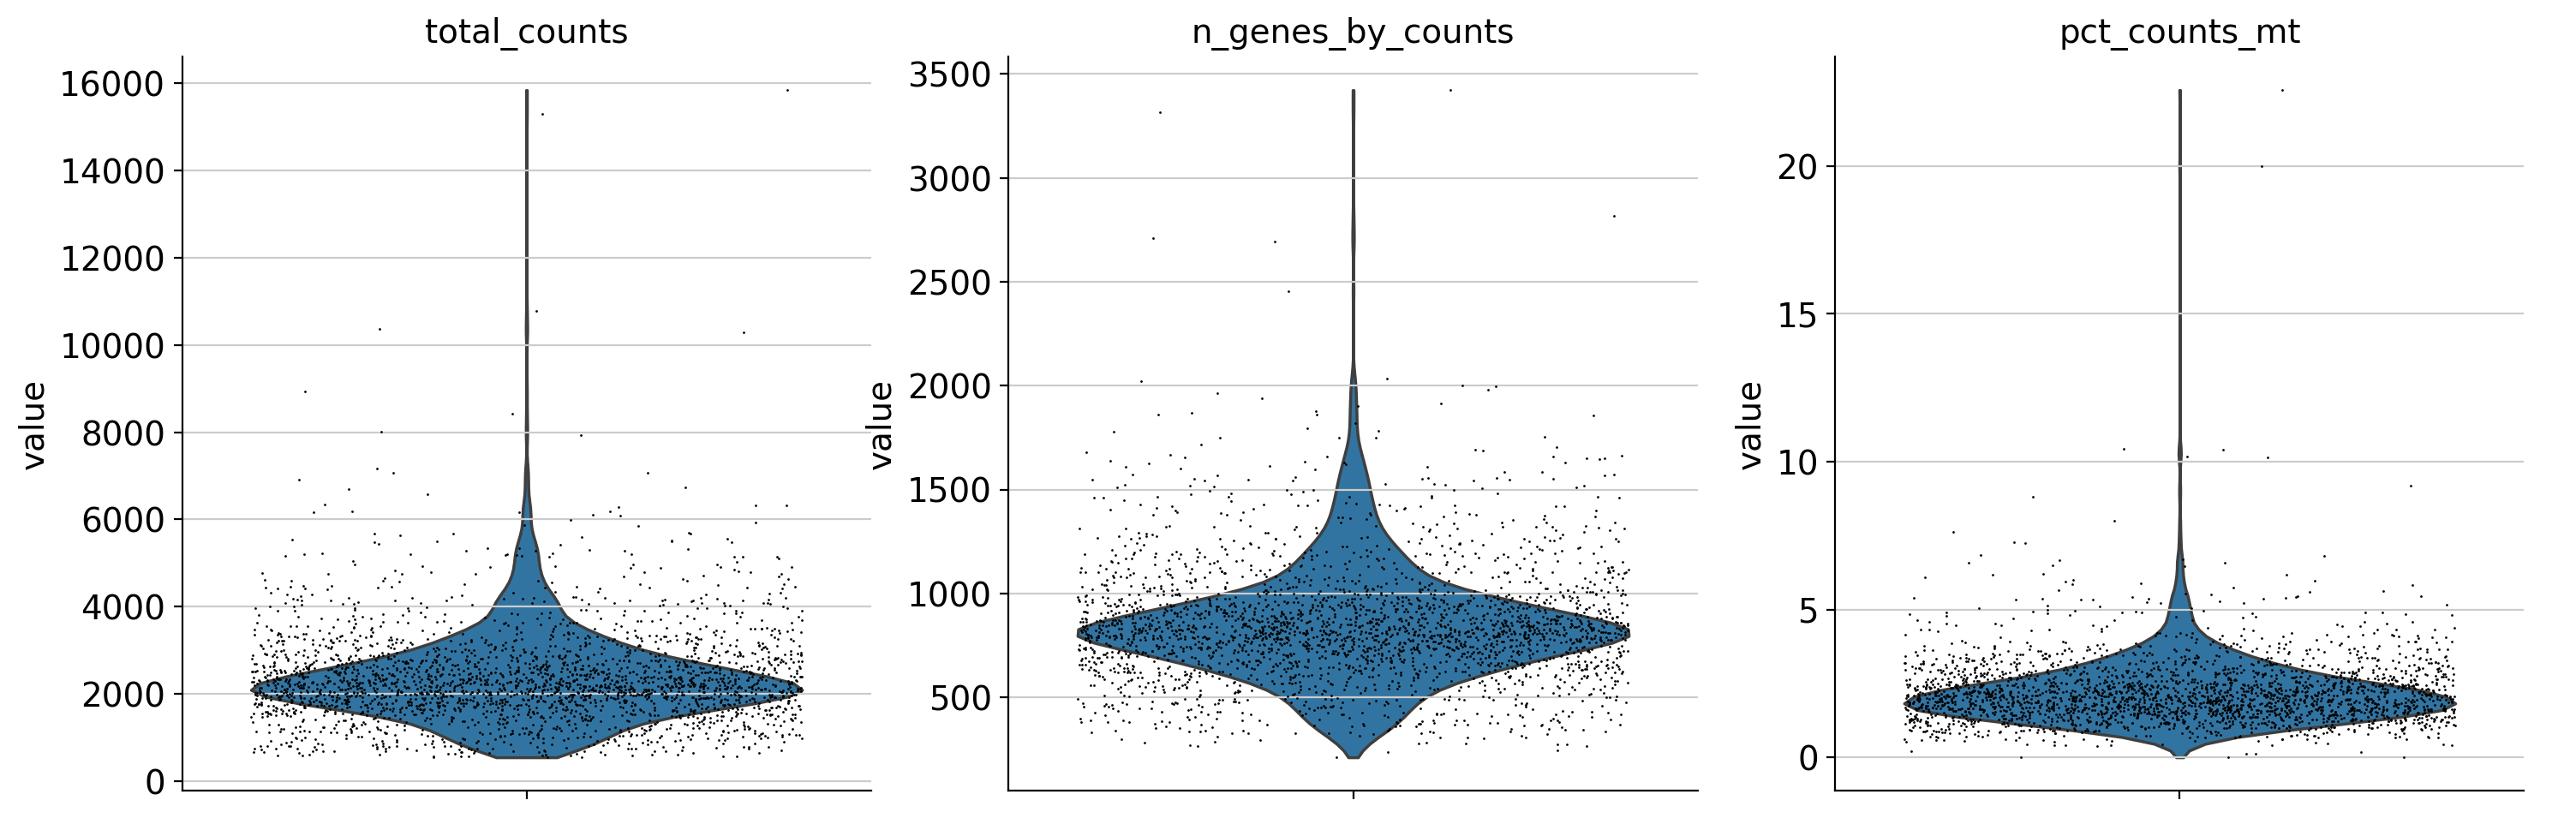

In [5]:
# Identify mitochondrial genes (human mitochondrial gene symbols begin with MT-)
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate per-cell QC metrics
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

sc.pl.violin(
    adata,
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

In [6]:
qc_columns = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
display(
    adata.obs[qc_columns]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(2)
)

print("Original number of cells:", adata.n_obs)
print("Cells with fewer than 200 genes:",
      (adata.obs["n_genes_by_counts"] < 200).sum())
print("Cells with more than 2500 genes:",
      (adata.obs["n_genes_by_counts"] > 2500).sum())
print("Cells with more than 5% mitochondrial counts:",
      (adata.obs["pct_counts_mt"] > 5).sum())

,total_counts,n_genes_by_counts,pct_counts_mt
count,2700.00,2700.00,2700.00
mean,2366.90,846.99,2.22
std,1094.26,282.10,1.17
min,548.00,212.00,0.00
1%,658.93,326.00,0.59
5%,955.95,435.95,0.93
25%,1757.75,690.00,1.54
50%,2197.00,817.00,2.03
75%,2763.00,953.25,2.64
95%,4220.55,1368.10,4.01


Original number of cells: 2700
Cells with fewer than 200 genes: 0
Cells with more than 2500 genes: 5
Cells with more than 5% mitochondrial counts: 57


In [7]:
# Keep a copy of the original data before filtering
adata_raw = adata.copy()

# Apply the filtering thresholds used in this project
adata = adata[
    (adata.obs["n_genes_by_counts"] >= 200) &
    (adata.obs["n_genes_by_counts"] <= 2500) &
    (adata.obs["pct_counts_mt"] <= 5)
].copy()

print("Cells before filtering:", adata_raw.n_obs)
print("Cells after filtering:", adata.n_obs)
print("Cells removed:", adata_raw.n_obs - adata.n_obs)
print("Percentage retained:",
      round(100 * adata.n_obs / adata_raw.n_obs, 2), "%")

Cells before filtering: 2700
Cells after filtering: 2638
Cells removed: 62
Percentage retained: 97.7 %


## 4. Normalize expression

The original count matrix is saved in `adata.layers["counts"]` before normalization. Then each cell is normalized to a total of 10,000 counts and log-transformed with `log1p`.

The normalized and log-transformed values are useful for many downstream visualization and marker-analysis tasks. They are not raw UMI counts.

In [8]:
# Preserve the unnormalized count data
adata.layers["counts"] = adata.X.copy()

# Normalize each cell to a total count of 10,000
sc.pp.normalize_total(adata, target_sum=1e4)

# Apply log(1 + x) transformation
sc.pp.log1p(adata)

print(adata)

normalizing counts per cell
    finished (0:00:13)
AnnData object with n_obs × n_vars = 2638 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'
    layers: 'counts'


## 5. Highly variable genes (HVGs)

Highly variable genes are genes whose expression varies strongly across cells. They are commonly used to focus dimensionality reduction on informative genes.

We select 2,000 highly variable genes and create a separate object, `adata_hvg`, for dimensionality reduction and clustering. The main `adata` object retains the full gene set for marker inspection and downstream comparisons.

extracting highly variable genes
    finished (0:00:03)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
Highly variable genes: 2000


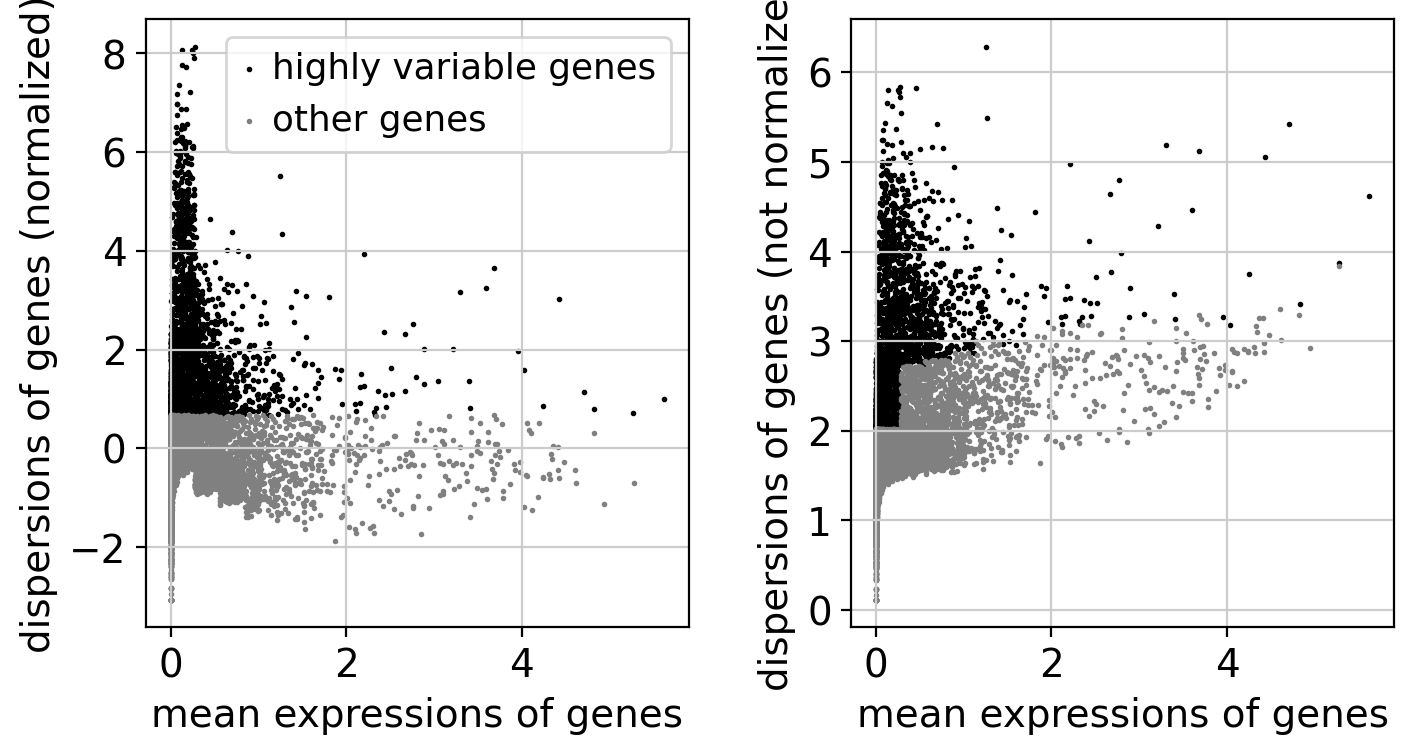

AnnData object with n_obs × n_vars = 2638 × 2000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: 'counts'


In [9]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print("Highly variable genes:",
      int(adata.var["highly_variable"].sum()))

sc.pl.highly_variable_genes(adata)

adata_hvg = adata[:, adata.var["highly_variable"]].copy()
print(adata_hvg)

## 6. Dimensionality reduction: scaling and PCA

PCA (principal component analysis) summarizes patterns of variation across genes into a smaller number of components. Here, the highly variable genes are scaled before PCA, with extreme scaled values clipped at 10.

We calculate 50 principal components and inspect the variance-ratio plot. The next step uses the first 30 components to build the neighbour graph, matching the original analysis.

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=50
    finished (0:00:04)


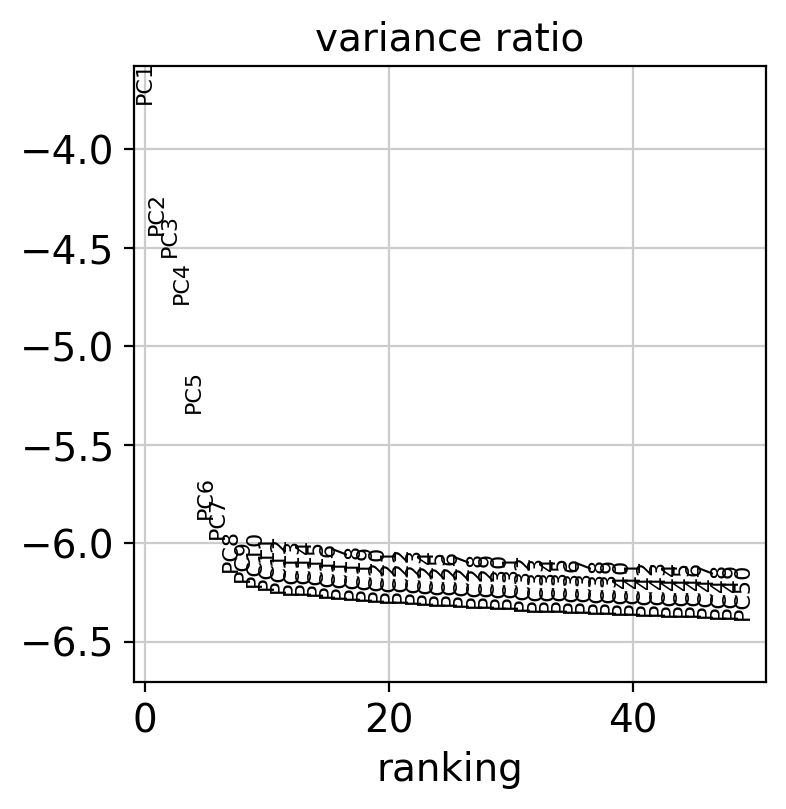

In [10]:
sc.pp.scale(adata_hvg, max_value=10)

sc.tl.pca(
    adata_hvg,
    n_comps=50,
    svd_solver="arpack",
    random_state=42
)

sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50, log=True)

Cumulative variance explained:
First 10 PCs: 7.03%
First 20 PCs: 8.92%
First 30 PCs: 10.72%
First 40 PCs: 12.47%
First 50 PCs: 14.17%


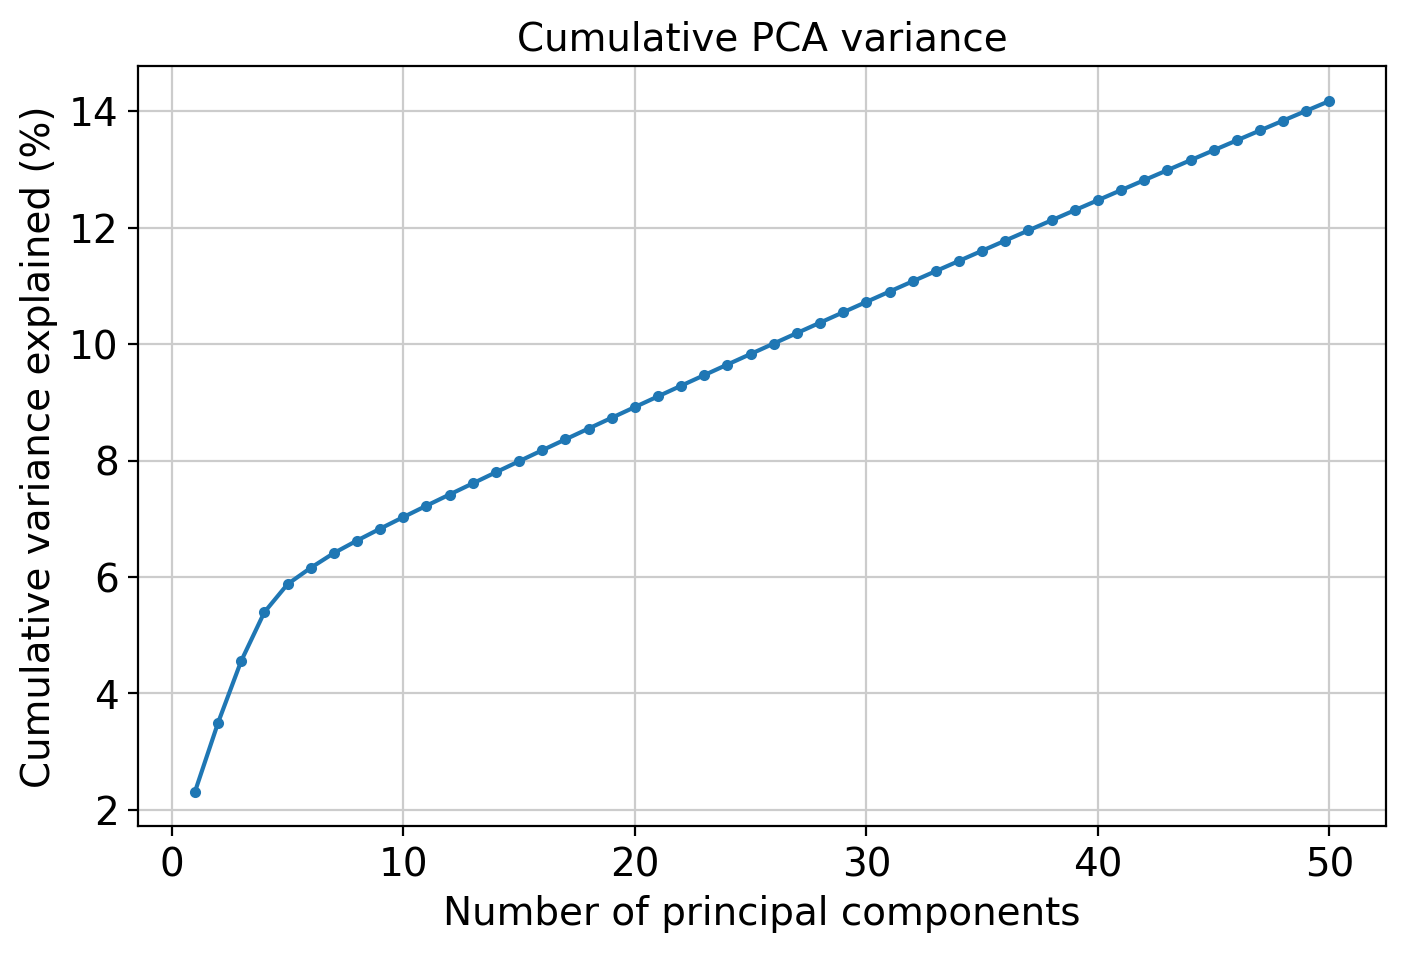

In [11]:
variance_ratio = adata_hvg.uns["pca"]["variance_ratio"]
cumulative_variance = np.cumsum(variance_ratio)

print("Cumulative variance explained:")
for n_pcs in [10, 20, 30, 40, 50]:
    print(f"First {n_pcs} PCs: {cumulative_variance[n_pcs - 1] * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="."
)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative variance explained (%)")
plt.title("Cumulative PCA variance")
plt.grid(True)
plt.show()

## 7. Neighbour graph, UMAP, and Leiden clustering

The neighbour graph connects cells with similar expression profiles in the PCA space. UMAP provides a two-dimensional visualization of this structure. Leiden clustering groups cells based on the neighbour graph.

UMAP axes do not have direct biological units; the plot is a visualization, not a map of physical cell positions.

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:44)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:05)
running Leiden clustering


/tmp/ipykernel_3957/1530100145.py:10: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


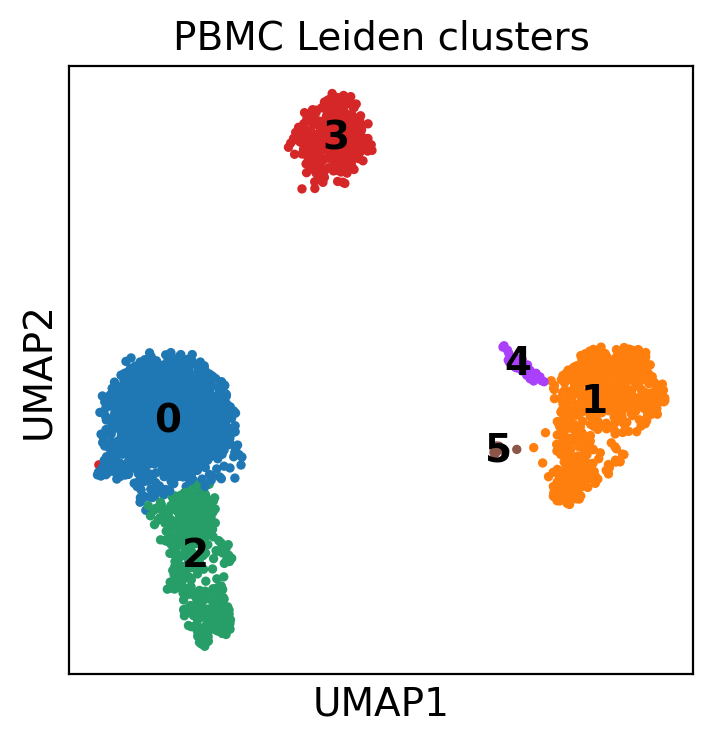

leiden
0    1184
1     639
2     421
3     345
4      36
5      13
Name: count, dtype: int64


In [12]:
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=10,
    n_pcs=30,
    random_state=42
)

sc.tl.umap(adata_hvg, random_state=42)

sc.tl.leiden(
    adata_hvg,
    resolution=0.5,
    random_state=42,
    key_added="leiden"
)

sc.pl.umap(
    adata_hvg,
    color="leiden",
    legend_loc="on data",
    title="PBMC Leiden clusters"
)

print(adata_hvg.obs["leiden"].value_counts().sort_index())

In [13]:
# Transfer cluster labels to the full-gene AnnData object
adata.obs["leiden"] = adata_hvg.obs["leiden"].copy()

## 8. Find marker genes for each cluster

Marker genes help interpret what cell populations may be present in each cluster.

**Analysis detail:** marker ranking is performed on `adata`, which contains normalized and log-transformed expression values. It is deliberately not performed on the scaled PCA input, because scaling can make fold-change summaries difficult to interpret and was associated with NaN log-fold-change values in the earlier notebook.

The Wilcoxon test here is a cell-level exploratory comparison. It should not be interpreted as donor-level statistical evidence.

ranking genes
    finished: added to `.uns['markers_unscaled']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:20)


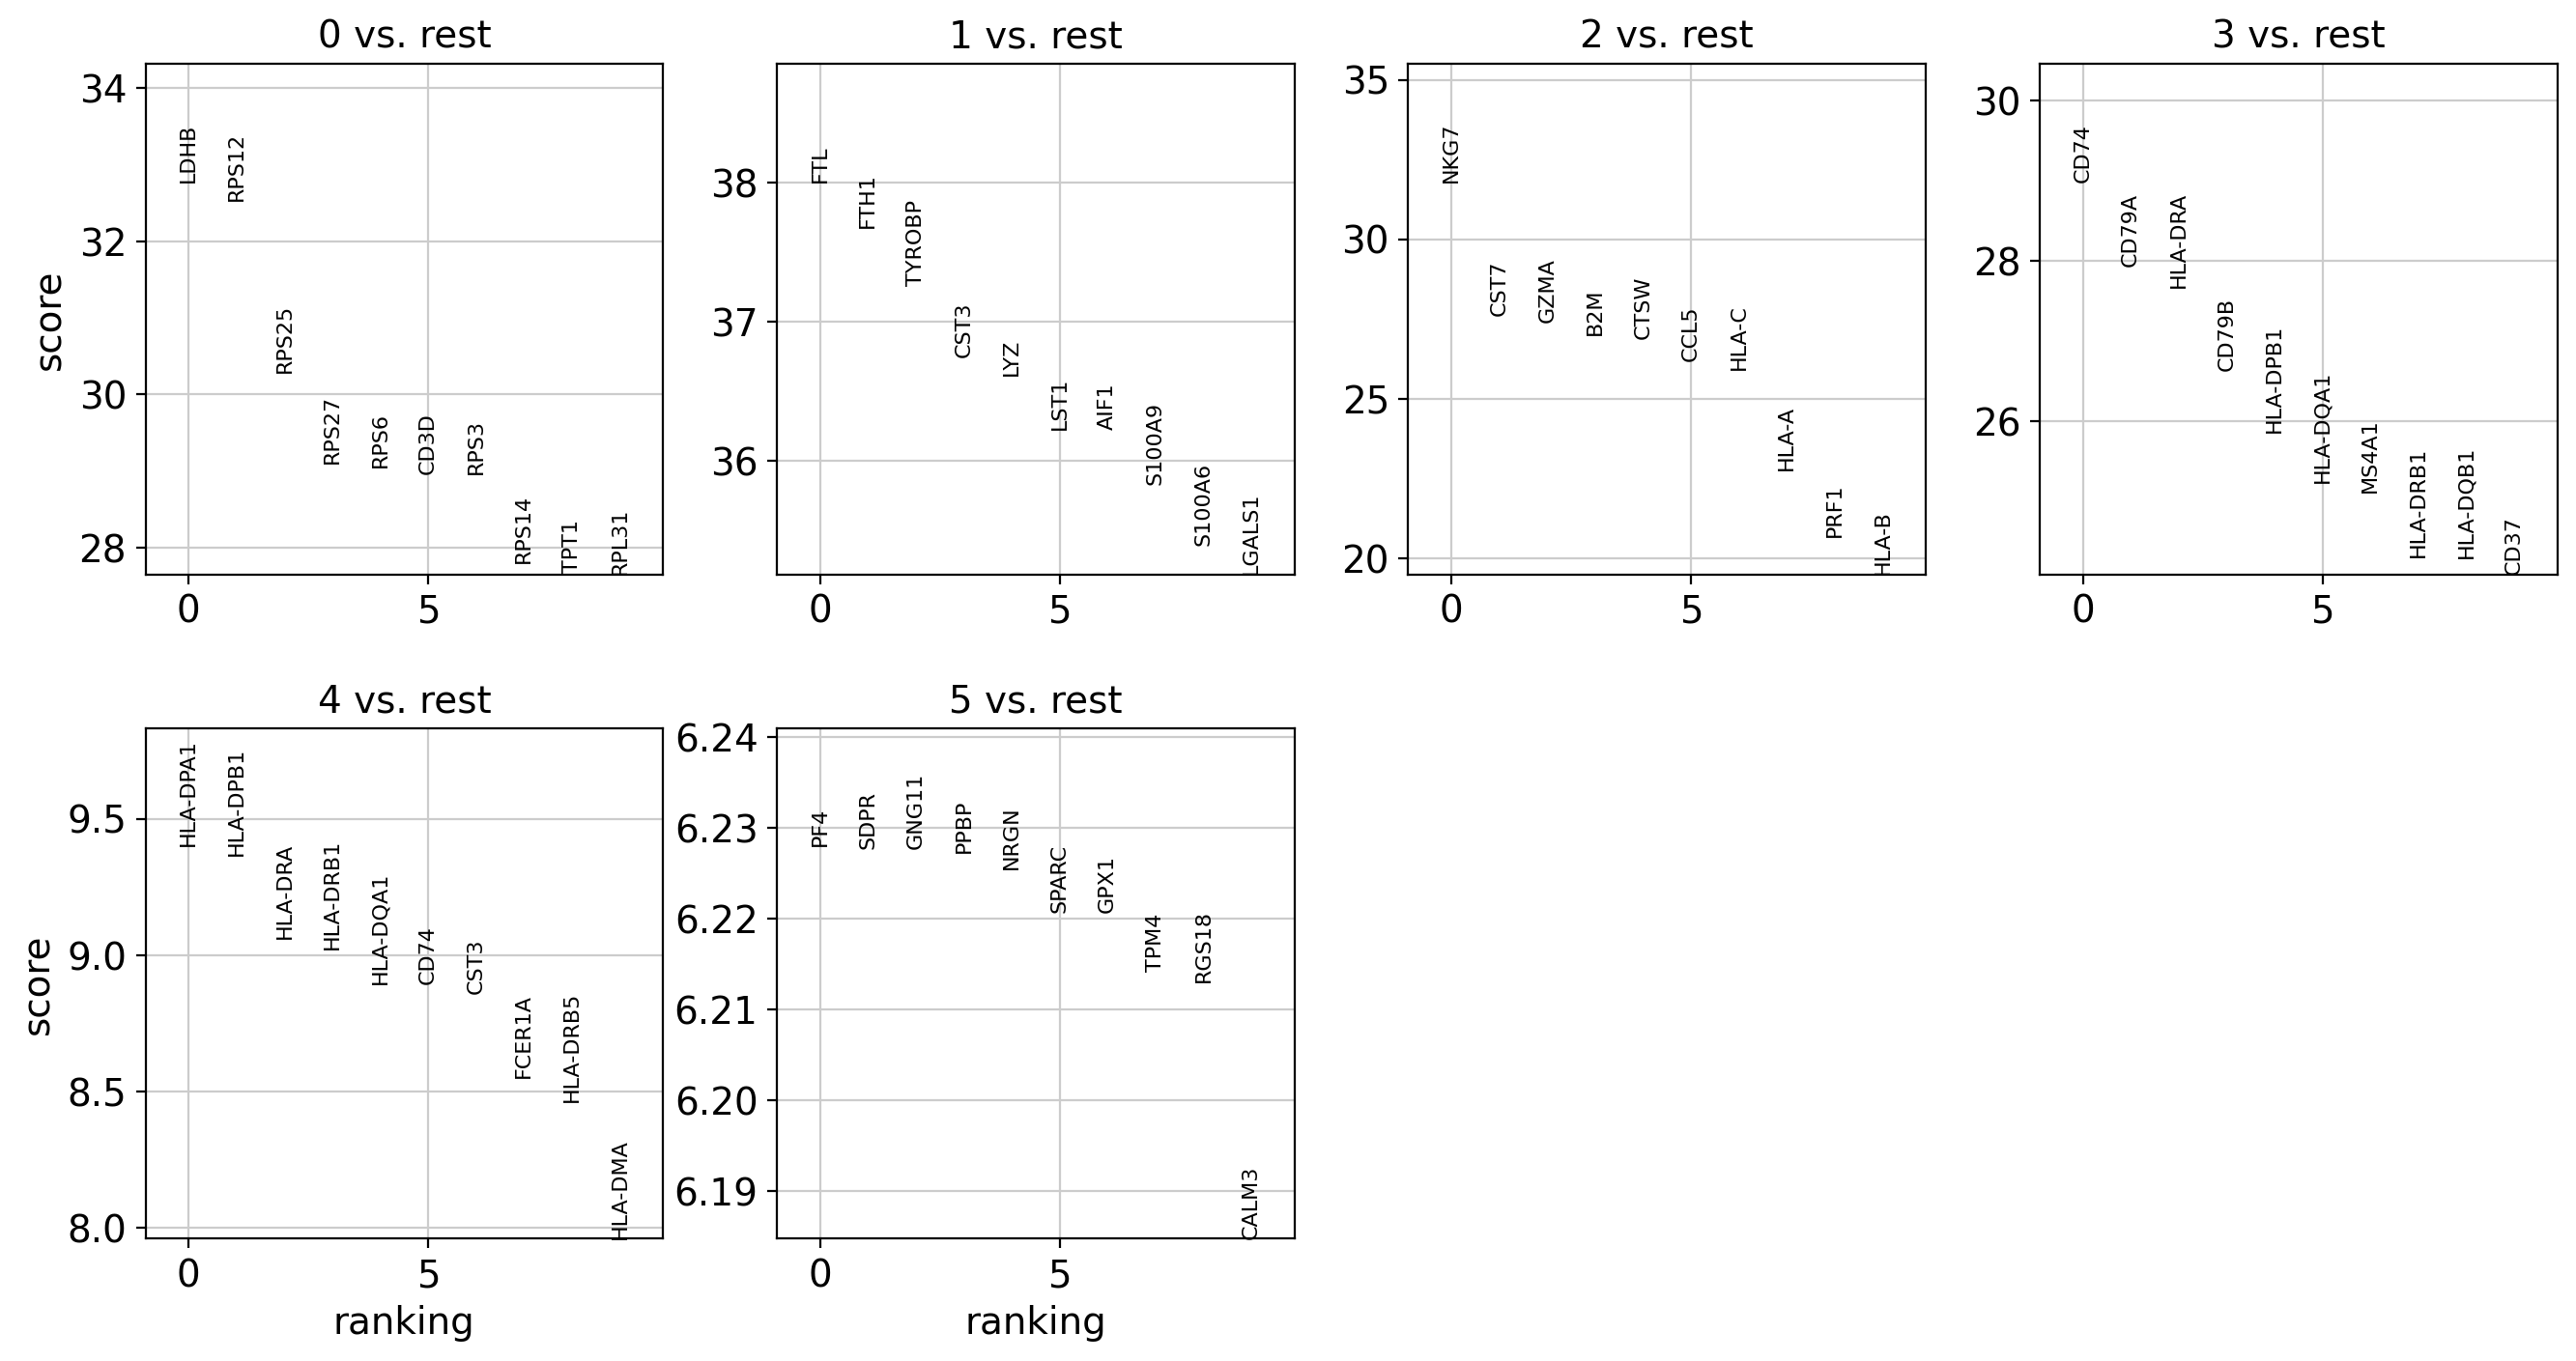

,group,names,scores,logfoldchanges,pvals_adj
0,0,LDHB,32.774269,2.774950,4.484716e-231
1,0,RPS12,32.528683,1.055758,6.862294e-228
2,0,RPS25,30.278139,1.175191,1.456409e-197
3,0,RPS27,29.103912,1.013296,1.310779e-182
4,0,RPS6,29.047379,0.867770,6.040734e-182
5,0,CD3D,28.963633,3.346373,6.187760e-181
6,0,RPS3,28.956823,0.879094,6.853150e-181
7,0,RPS14,27.801561,0.769407,9.711873e-167
8,0,TPT1,27.671638,0.941625,3.345154e-165
9,0,RPL31,27.642086,1.125746,7.108875e-165


In [14]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    key_added="markers_unscaled"
)

sc.pl.rank_genes_groups(
    adata,
    key="markers_unscaled",
    n_genes=10,
    sharey=False
)

markers = sc.get.rank_genes_groups_df(
    adata,
    group=None,
    key="markers_unscaled"
)

display(
    markers.groupby("group", observed=True)
    .head(10)[["group", "names", "scores", "logfoldchanges", "pvals_adj"]]
)

## 9. Inspect known marker genes and assign broad cell types

We inspect a panel of commonly used PBMC marker genes. The cluster-to-cell-type mapping below follows the marker interpretation in this project. Cluster numbers are dataset- and parameter-dependent; they are not universal cell-type identifiers.

Available marker genes: ['CD3D', 'CD3E', 'LTB', 'MS4A1', 'CD79A', 'CD74', 'NKG7', 'GNLY', 'PRF1', 'LYZ', 'LST1', 'S100A9', 'FCER1A', 'CST3', 'PF4', 'PPBP']


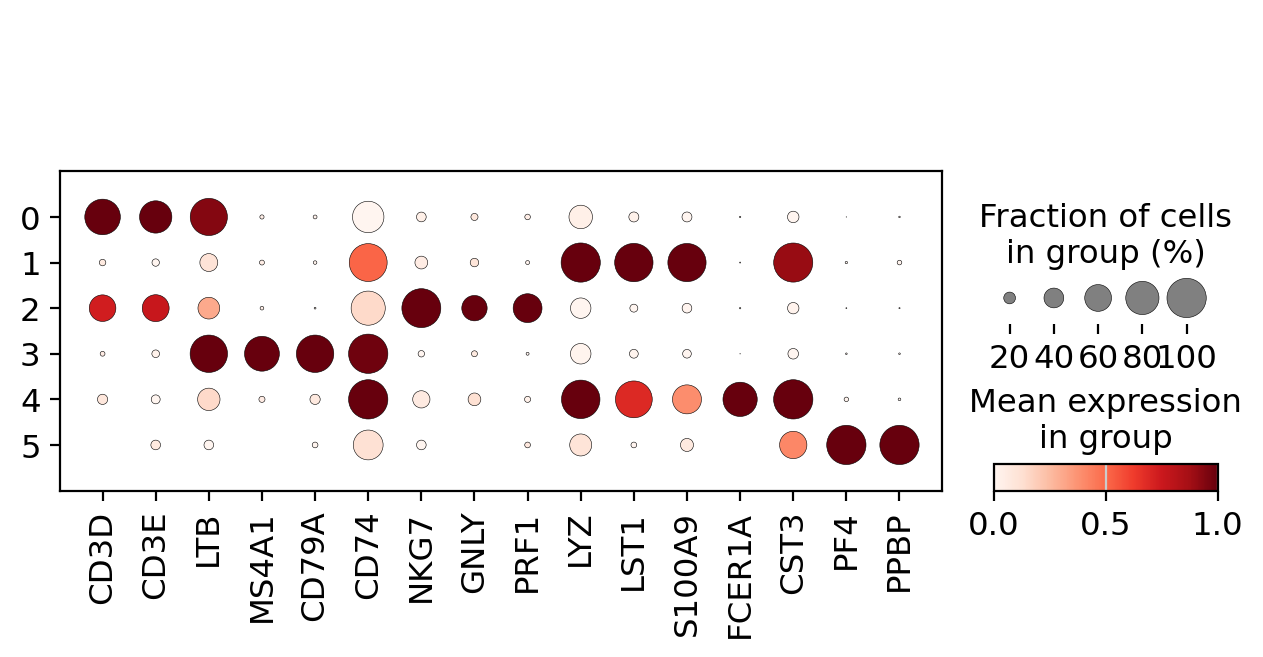

In [15]:
marker_genes = [
    "CD3D", "CD3E", "LTB",       # T-cell-associated
    "MS4A1", "CD79A", "CD74",    # B-cell-associated
    "NKG7", "GNLY", "PRF1",      # cytotoxic lymphocyte-associated
    "LYZ", "LST1", "S100A9",     # monocyte-associated
    "FCER1A", "CST3",            # dendritic-cell-associated
    "PF4", "PPBP"                # platelet-associated
]

available_marker_genes = [
    gene for gene in marker_genes if gene in adata.var_names
]
print("Available marker genes:", available_marker_genes)

sc.pl.dotplot(
    adata,
    available_marker_genes,
    groupby="leiden",
    standard_scale="var"
)

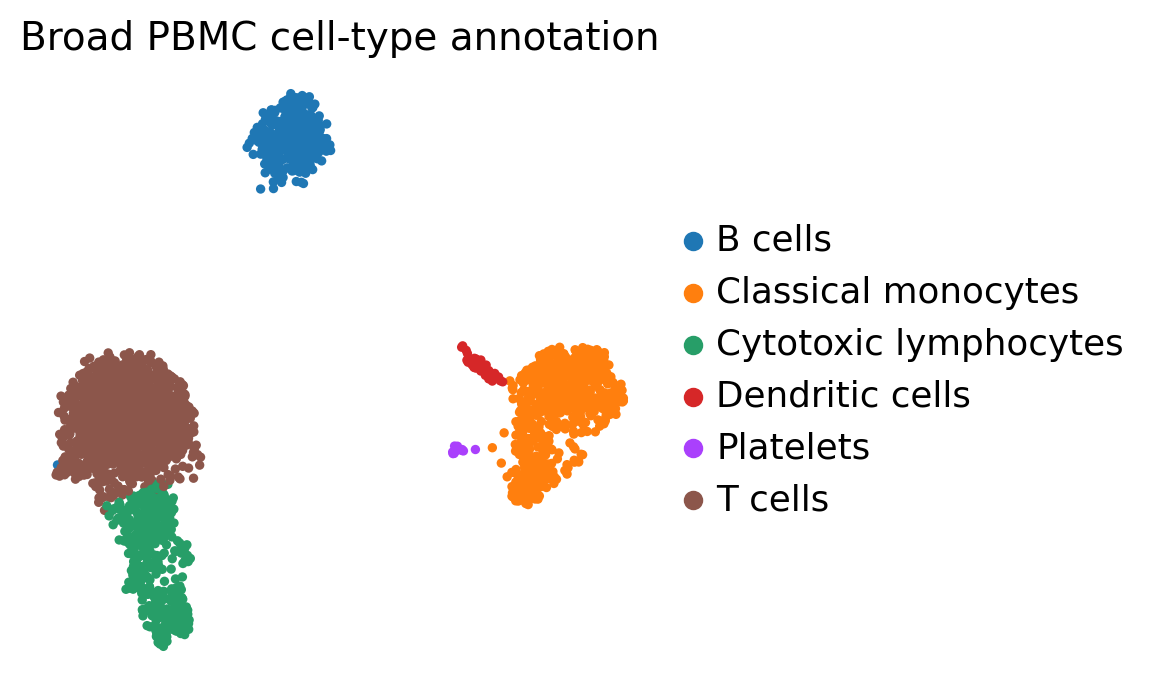

In [16]:
cell_type_map = {
    "0": "T cells",
    "1": "Classical monocytes",
    "2": "Cytotoxic lymphocytes",
    "3": "B cells",
    "4": "Dendritic cells",
    "5": "Platelets"
}

adata.obs["cell_type"] = (
    adata.obs["leiden"].astype(str).map(cell_type_map)
)

adata_hvg.obs["cell_type"] = adata.obs["cell_type"].copy()

sc.pl.umap(
    adata_hvg,
    color="cell_type",
    title="Broad PBMC cell-type annotation",
    legend_loc="right margin",
    frameon=False
)

## 10. Explore the cytotoxic lymphocyte cluster

Cluster 2 shows cytotoxic-lymphocyte-associated expression in this analysis. We inspect T-cell-associated markers (such as CD3D, CD3E, and TRAC) alongside NK/cytotoxic-associated markers (such as NKG7, GNLY, and KLRD1).

The next split uses CD3D detection as a simple exploratory rule:
- CD3D detected: cytotoxic T-cell candidate
- CD3D not detected: NK-cell candidate

**Caution:** absence of detected CD3D does not prove that a cell is an NK cell. Dropout, expression level, and biological heterogeneity can affect detection. A robust annotation should consider multiple markers and, where possible, reference-based methods or protein measurements.

In [17]:
cluster2 = adata[
    adata.obs["leiden"].astype(str) == "2"
].copy()

cd3d_values = np.asarray(cluster2[:, "CD3D"].X.toarray()).ravel()
nkg7_values = np.asarray(cluster2[:, "NKG7"].X.toarray()).ravel()

print("Cells in cluster 2:", cluster2.n_obs)
print("CD3D-positive cells:", int((cd3d_values > 0).sum()))
print("NKG7-positive cells:", int((nkg7_values > 0).sum()))
print("CD3D and NKG7 double-positive cells:",
      int(((cd3d_values > 0) & (nkg7_values > 0)).sum()))

Cells in cluster 2: 421
CD3D-positive cells: 250
NKG7-positive cells: 416
CD3D and NKG7 double-positive cells: 245


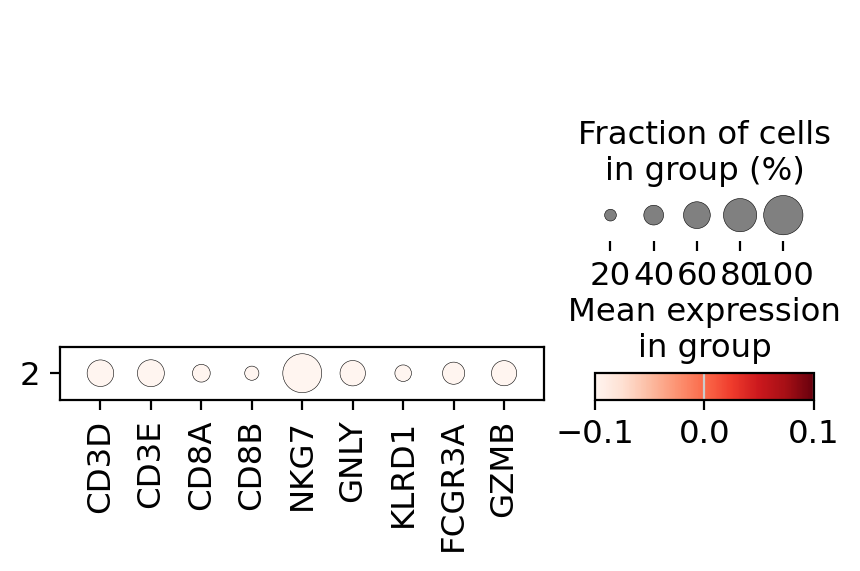

In [18]:
nk_t_markers = [
    "CD3D", "CD3E", "TRBC1", "TRBC2", "CD8A", "CD8B",
    "NKG7", "GNLY", "KLRD1", "FCGR3A", "GZMB"
]
available_nk_t_markers = [
    gene for gene in nk_t_markers if gene in cluster2.var_names
]

sc.pl.dotplot(
    cluster2,
    available_nk_t_markers,
    groupby="leiden",
    standard_scale="var"
)

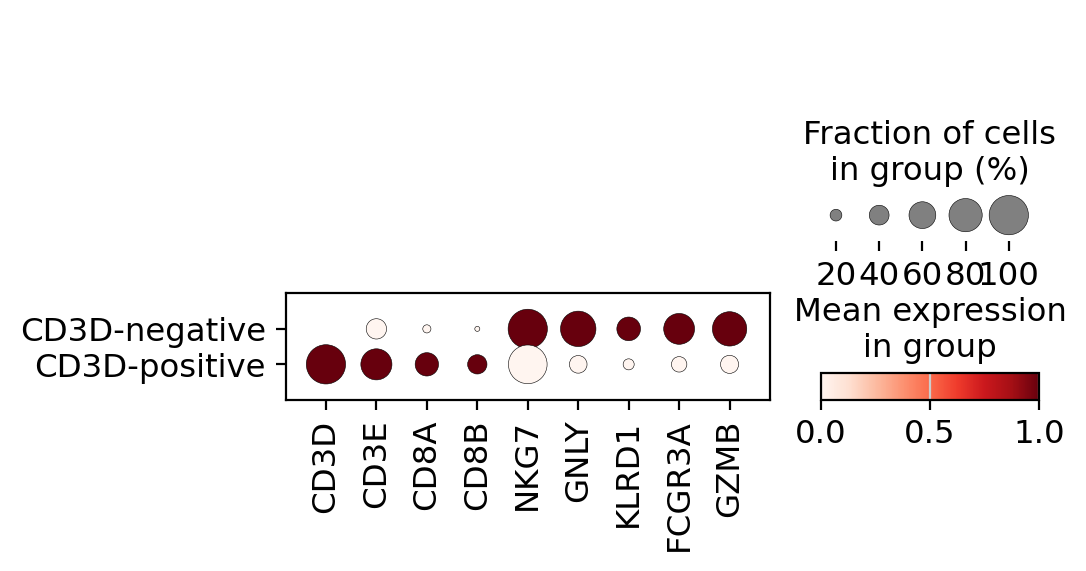

In [19]:
cluster2.obs["candidate_group"] = np.where(
    np.asarray(cluster2[:, "CD3D"].X.toarray()).ravel() > 0,
    "CD3D-positive",
    "CD3D-negative"
)

sc.pl.dotplot(
    cluster2,
    available_nk_t_markers,
    groupby="candidate_group",
    standard_scale="var"
)

## 11. Create provisional refined labels

The broad labels are retained for the other clusters. Cluster 2 is divided into the two provisional candidate groups described above. These labels should be read as candidate populations rather than definitive identities.

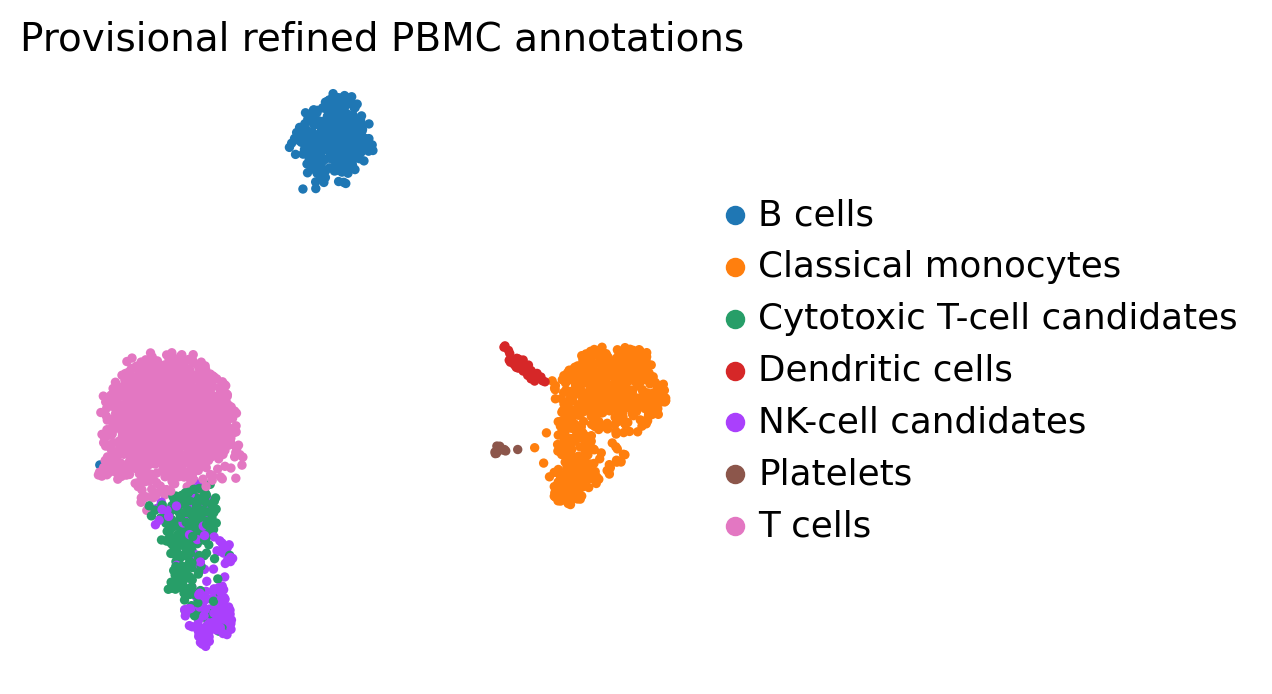

In [20]:
adata.obs["cell_type_refined"] = (
    adata.obs["leiden"].astype(str).map(cell_type_map)
)

cluster2_mask = adata.obs["leiden"].astype(str) == "2"
cluster2_cd3d = np.asarray(
    adata[cluster2_mask, "CD3D"].X.toarray()
).ravel()

adata.obs.loc[cluster2_mask, "cell_type_refined"] = np.where(
    cluster2_cd3d > 0,
    "Cytotoxic T-cell candidates",
    "NK-cell candidates"
)

adata_hvg.obs["cell_type_refined"] = (
    adata.obs["cell_type_refined"].copy()
)

sc.pl.umap(
    adata_hvg,
    color="cell_type_refined",
    title="Provisional refined PBMC annotations",
    legend_loc="right margin",
    frameon=False
)

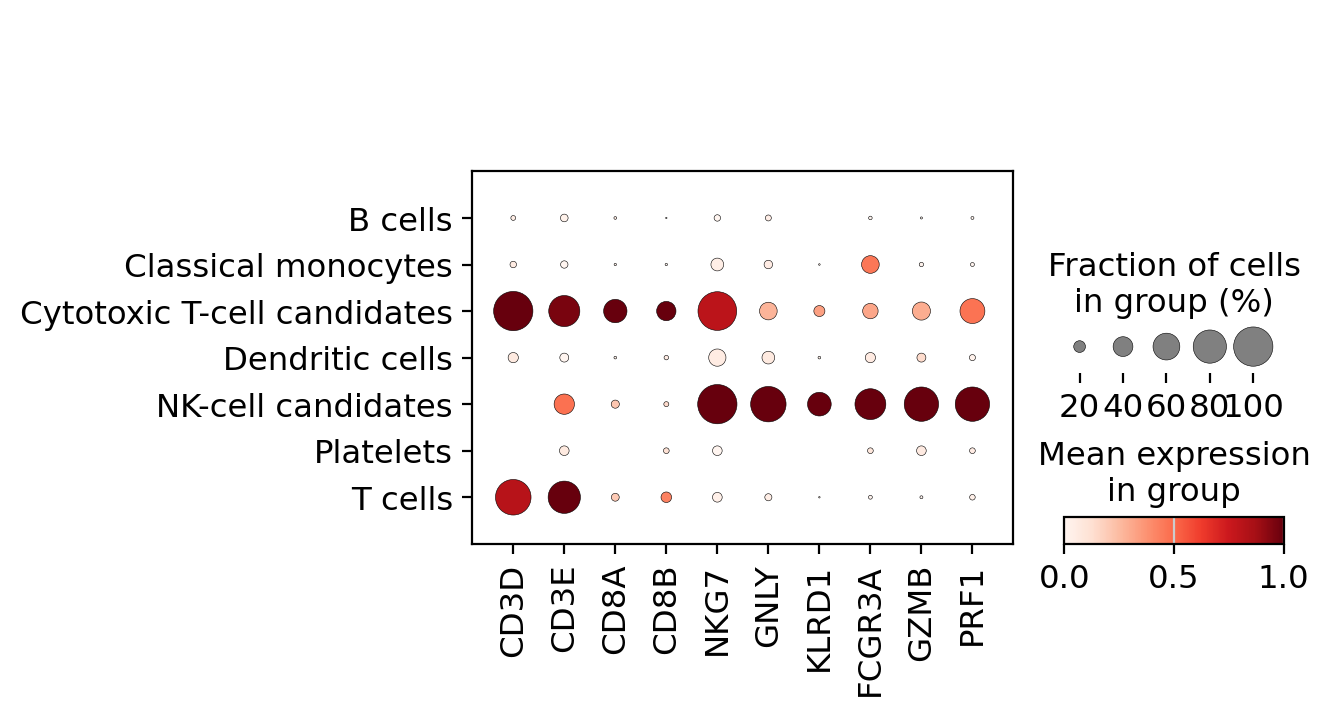

cell_type_refined
T cells                        1184
Classical monocytes             639
B cells                         345
Cytotoxic T-cell candidates     250
NK-cell candidates              171
Dendritic cells                  36
Platelets                        13
Name: count, dtype: int64


In [21]:
validation_markers = [
    "CD3D", "CD3E", "TRAC", "TRBC1", "TRBC2",
    "CD8A", "CD8B", "NKG7", "GNLY", "KLRD1",
    "FCGR3A", "GZMB", "PRF1"
]
available_validation_markers = [
    gene for gene in validation_markers if gene in adata.var_names
]

sc.pl.dotplot(
    adata,
    available_validation_markers,
    groupby="cell_type_refined",
    standard_scale="var"
)

print(adata.obs["cell_type_refined"].value_counts())

## 12. Summarize cell-type counts and save the annotated data

The summary table reports the number and percentage of retained cells assigned to each provisional label. The annotated AnnData object is saved as an `.h5ad` file for reuse.

In [22]:
cell_counts = adata.obs["cell_type_refined"].value_counts()
cell_percentages = cell_counts / adata.n_obs * 100

cell_summary = pd.DataFrame({
    "Cell_Count": cell_counts,
    "Percentage": cell_percentages
})

display(cell_summary.round(2))

os.makedirs("results/figures", exist_ok=True)

adata.write_h5ad("results/PBMC_annotated.h5ad")
cell_summary.to_csv("results/PBMC_cell_type_counts.csv")
print("Saved annotated AnnData and cell-type summary.")

,Cell_Count,Percentage
cell_type_refined,,
T cells,1184,44.88
Classical monocytes,639,24.22
B cells,345,13.08
Cytotoxic T-cell candidates,250,9.48
NK-cell candidates,171,6.48
Dendritic cells,36,1.36
Platelets,13,0.49


Saved annotated AnnData and cell-type summary.


## 13. Exploratory differential expression: NK candidates vs cytotoxic T-cell candidates

We compare the two provisional candidate groups using the Wilcoxon rank-sum test implemented by Scanpy. The expression values are normalized and log-transformed values from `adata`; `use_raw=False` makes this explicit.

This is an exploratory, cell-level comparison within this PBMC dataset. It is not a substitute for donor-aware differential-expression analysis. Very large log-fold changes can occur when a gene is detected in one group but rarely or never detected in the reference group, so inspect expression patterns as well as statistical rankings.

In [23]:
dge_adata = adata[
    adata.obs["cell_type_refined"].isin([
        "Cytotoxic T-cell candidates",
        "NK-cell candidates"
    ])
].copy()

print(dge_adata.obs["cell_type_refined"].value_counts())

cell_type_refined
Cytotoxic T-cell candidates    250
NK-cell candidates             171
Name: count, dtype: int64


ranking genes
    finished: added to `.uns['nk_vs_t']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


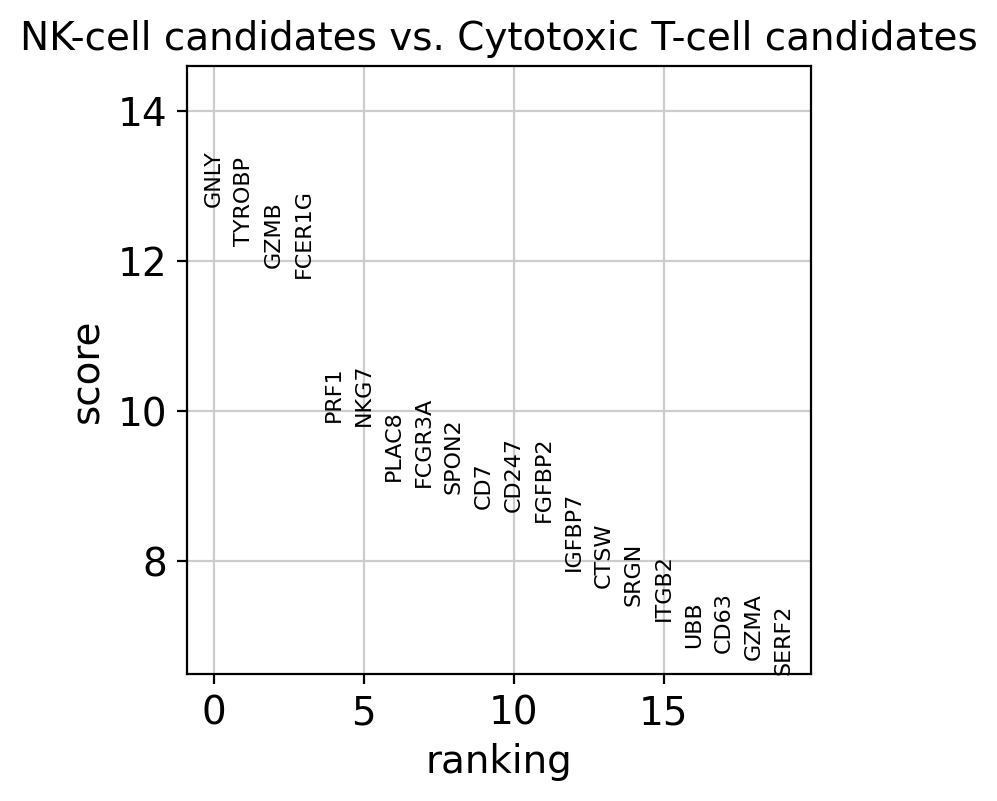

,names,scores,logfoldchanges,pvals_adj
0,GNLY,12.726304,4.647616,6.913712e-33
1,TYROBP,12.210449,3.970573,2.983245e-30
2,GZMB,11.913579,3.768971,8.230875e-29
3,FCER1G,11.781455,4.489532,3.185159e-28
4,PRF1,9.860357,2.311650,2.249070e-19
5,NKG7,9.801636,1.259124,3.626634e-19
6,PLAC8,9.074546,2.190066,2.198305e-16
7,FCGR3A,8.984016,2.637693,4.498167e-16
8,SPON2,8.891041,3.277641,9.909663e-16
9,CD7,8.692855,1.997111,4.628418e-15


In [24]:
sc.tl.rank_genes_groups(
    dge_adata,
    groupby="cell_type_refined",
    groups=["NK-cell candidates"],
    reference="Cytotoxic T-cell candidates",
    method="wilcoxon",
    use_raw=False,
    pts=True,
    key_added="nk_vs_t"
)

sc.pl.rank_genes_groups(
    dge_adata,
    groups=["NK-cell candidates"],
    key="nk_vs_t",
    n_genes=20,
    sharey=False
)

nk_vs_t = sc.get.rank_genes_groups_df(
    dge_adata,
    group="NK-cell candidates",
    key="nk_vs_t"
)

display(
    nk_vs_t[
        ["names", "scores", "logfoldchanges", "pvals_adj"]
    ].head(20)
)

ranking genes
    finished: added to `.uns['tcell_vs_nk']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


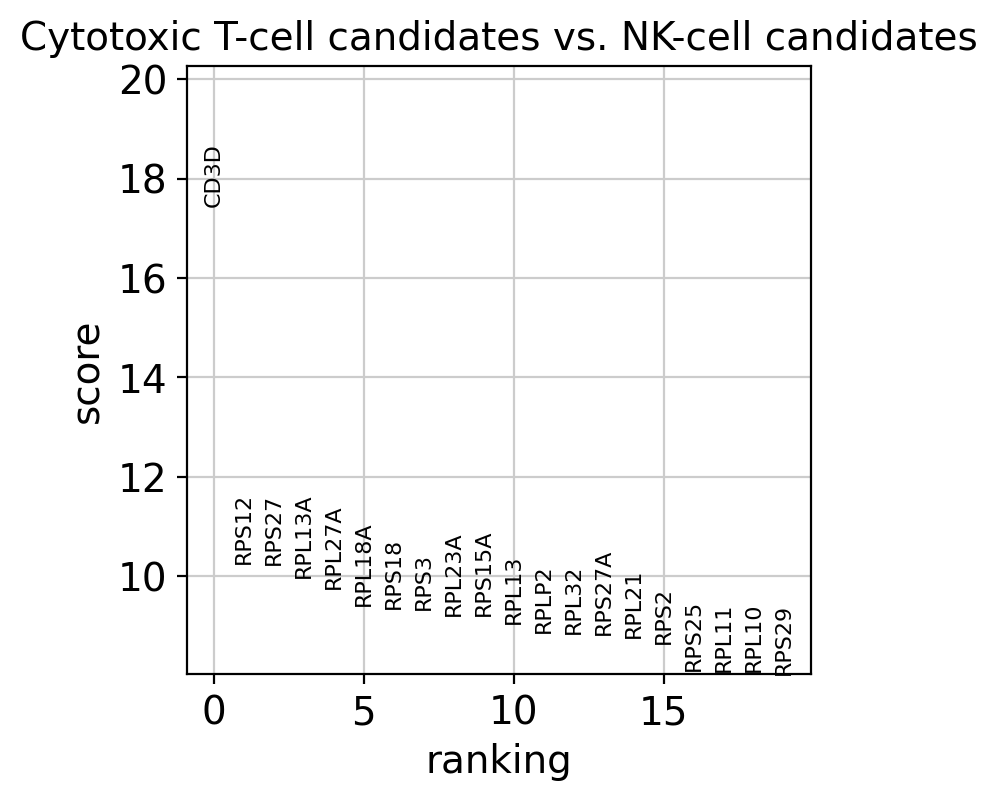

,names,scores,logfoldchanges,pvals_adj
0,CD3D,17.433014,33.569298,1.517031e-63
1,RPS12,10.255506,0.991047,6.099623e-21
2,RPS27,10.233892,0.919075,6.537565e-21
3,RPL13A,9.976170,0.714825,7.930987e-20
4,RPL27A,9.744952,0.923402,5.769910e-19
5,RPL18A,9.398739,0.860625,1.506518e-17
6,RPS18,9.336755,0.735067,2.501482e-17
7,RPS3,9.315958,0.684988,2.826162e-17
8,RPL23A,9.204224,0.838293,7.511216e-17
9,RPS15A,9.194844,0.796180,7.683995e-17


In [25]:
sc.tl.rank_genes_groups(
    dge_adata,
    groupby="cell_type_refined",
    groups=["Cytotoxic T-cell candidates"],
    reference="NK-cell candidates",
    method="wilcoxon",
    use_raw=False,
    pts=True,
    key_added="tcell_vs_nk"
)

sc.pl.rank_genes_groups(
    dge_adata,
    groups=["Cytotoxic T-cell candidates"],
    key="tcell_vs_nk",
    n_genes=20,
    sharey=False
)

tcell_vs_nk = sc.get.rank_genes_groups_df(
    dge_adata,
    group="Cytotoxic T-cell candidates",
    key="tcell_vs_nk"
)

display(
    tcell_vs_nk[
        ["names", "scores", "logfoldchanges", "pvals_adj"]
    ].head(20)
)

## 14. Export differential-expression tables

The CSV files are saved in the `results/` directory. In Google Colab, use the Files panel to download them, or download them with the optional cell below.

In [26]:
nk_vs_t.to_csv(
    "results/NK_candidates_vs_Cytotoxic_T_candidates.csv",
    index=False
)
tcell_vs_nk.to_csv(
    "results/Cytotoxic_T_candidates_vs_NK_candidates.csv",
    index=False
)

print("Result files:")
for filename in sorted(os.listdir("results")):
    print("-", filename)

Result files:
- Cytotoxic_T_candidates_vs_NK_candidates.csv
- NK_candidates_vs_Cytotoxic_T_candidates.csv
- PBMC_annotated.h5ad
- PBMC_cell_type_counts.csv
- figures


### Optional: download result files from Google Colab

Run this cell only if you want to download the CSV files to your computer. It is not required for the analysis itself.

In [27]:
from google.colab import files

files.download("results/PBMC_cell_type_counts.csv")
files.download("results/NK_candidates_vs_Cytotoxic_T_candidates.csv")
files.download("results/Cytotoxic_T_candidates_vs_NK_candidates.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Interpretation and limitations

- The workflow retained cells using the stated QC thresholds; QC thresholds are dataset-specific.
- Broad cluster labels were assigned using marker-gene patterns.
- The NK/T split is provisional because it uses CD3D detection as a simple rule.
- Differential-expression results are exploratory and cell-level. If multiple biological donors are available, donor-aware pseudobulk analysis is generally preferable for population-level inference.
- UMAP is a visualization of similarity structure; distances and axes should not be interpreted as direct biological measurements.

## Reproducibility note

Record the date of analysis and any changes to package versions, filtering thresholds, clustering parameters, or annotation rules when updating this notebook.